

| Bước | Nhiệm vụ | 
|---|---|
| 2.4.1 | Nạp dữ liệu đã làm sạch |
| 2.4.2 | Chọn thuộc tính khai phá | 
| 2.4.3 | Giảm bớt thuộc tính (lọc kỹ năng hiếm) | 
| 2.4.4 | One-hot encoding |
| 2.4.5 | Khai phá tập phổ biến bằng Apriori |
| 2.4.6 | Khai phá bằng FP-Growth & so sánh |
| 2.4.7 | Sinh luật kết hợp |
| 2.4.8 | Lọc luật |
| 2.4.8b | Loại luật dư thừa |
| 2.4.9 | Xem top luật | 
| 2.4.10 | Kiểm tra luật cụ thể theo chủ đề |
| 2.4.10b | Cùng một luật, hai mẫu số |
| 2.4.11 | Phát hiện luật gây nhiễu | 
| 2.4.11b | `MIN_COUNT` có thật sự ảnh hưởng? |
| 2.4.12 | Trực quan hóa | 

# BƯỚC 2.4.1 : NẠP DỮ LIỆU VÀO 

In [1]:
import os
import time
import json
import warnings

warnings.filterwarnings('ignore')
import pandas as pd 
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
    apriori,
    fpgrowth,
    association_rules
)

# Đọc dữ liệu đã qua bước Cleaning
input_file = '../buoc2.1_2.2/data/processed/clean_data_processed.csv'

if not os.path.exists(input_file):
    raise FileNotFoundError(f"Không tìm thấy file: {input_file}")

df_all = pd.read_csv(input_file, encoding='utf-8')

# Dùng cùng bộ lọc với bước 2.2 và 2.3: thuộc phạm vi IT sơ bộ VÀ có JD sạch
in_scope = df_all['scope_status'].eq('included_provisional')
has_jd = df_all['has_jd_clean'].eq(True)
df = df_all.loc[in_scope & has_jd].copy()

# Kiểm tra dữ liệu
print("File:", input_file)
print("Số bản ghi trong file:", len(df_all), "| số cột:", df_all.shape[1])
print("Thuộc phạm vi IT sơ bộ (included_provisional):", int(in_scope.sum()),
      "| còn chờ xác nhận (pending_review):", int((~in_scope).sum()))
print("Trong phạm vi VÀ có JD sạch (dùng để khai phá):", len(df))
print("Số tin theo nguồn:", df['source'].value_counts().to_dict())
print("Danh sách cột:", df.columns.tolist())

display(df.head())


File: ../buoc2.1_2.2/data/processed/clean_data_processed.csv
Số bản ghi trong file: 3135 | số cột: 47
Thuộc phạm vi IT sơ bộ (included_provisional): 2869 | còn chờ xác nhận (pending_review): 266
Trong phạm vi VÀ có JD sạch (dùng để khai phá): 2843
Số tin theo nguồn: {'topcv': 1138, 'linkedin': 637, 'itviec': 530, 'vietnamworks': 477, 'topdev': 61}
Danh sách cột: ['job_uid', 'job_group_id', 'source', 'URL_Goc', 'Timestamp', 'posted_date', 'posted_date_source', 'title', 'company', 'it_decision_source', 'title_role', 'work_mode_source', 'exp_min_years', 'exp_max_years', 'exp_source', 'Luong_Min', 'Luong_Max', 'Luong_TB', 'salary_status', 'salary_currency_orig', 'salary_period_assumed', 'salary_source', 'languages', 'benefits', 'jd_chars', 'scope_status', 'salary_invalid_bounds', 'salary_status_conflict', 'salary_eda_eligible', 'salary_eda_conservative', 'cities_clean', 'n_cities', 'work_mode_clean', 'experience_review', 'experience_group', 'seniority_clean', 'seniority_basis', 'intern_fla

,job_uid,job_group_id,source,URL_Goc,Timestamp,posted_date,posted_date_source,title,company,it_decision_source,...,intern_flag_review,description_clean,has_jd_clean,tech_list,keywords_list,skills,broad_concepts,application_domains,n_skills,text_for_tfidf
0,itviec-b9bccb83ab,g38788d35,itviec,https://itviec.com/it-jobs/manual-quality-assu...,2026-11-17T18:09:16+07:00,11/10/2026,field,Manual Quality Assurance (Senior/Lead),VinSmart Future,filter,...,False,Top 3 Reasons To Join Us Competitive Salary & ...,True,"[""Jira"", ""SQL""]","[""Azure"", ""DevOps""]","[""Azure"", ""DevOps"", ""Jira"", ""SQL""]",[],[],4,reasons join competitive salary benefits train...
1,itviec-ea14bd1d88,gb2b041c2,itviec,https://itviec.com/it-jobs/senior-data-scienti...,2026-11-17T18:09:16+07:00,10/27/2026,field,Senior Data Scientist - GSM Platform,VinSmart Future,filter,...,False,Top 3 Reasons To Join Us Competitive Salary & ...,True,"[""Python"", ""SQL"", ""Spark""]","[""Computer Vision"", ""Machine Learning""]","[""Computer Vision"", ""Machine Learning"", ""Pytho...",[],[],5,reasons join competitive salary benefits train...
2,itviec-99df719b7e,gb9e2c43d,itviec,https://itviec.com/it-jobs/japanese-tester-qa-...,2026-11-17T18:09:16+07:00,11/10/2026,field,Japanese Tester (QA/QC),Kobo Asia,filter,...,False,Top 3 Reasons To Join Us Cùng nhau thử thách v...,True,"[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]","[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]",[],4,reasons join cùng nhau thử thách kĩ thuật mới ...
3,itviec-8f816367b4,g0774918e,itviec,https://itviec.com/it-jobs/senior-application-...,2026-11-17T18:09:16+07:00,11/7/2026,field,Senior Application Operations Engineer (SysOps),Ngân hàng TMCP Tiên Phong | TPBank,filter,...,False,Top 3 Reasons To Join Us Thưởng dự án và thưởn...,True,"[""Kubernetes"", ""Linux""]","[""DevOps""]","[""DevOps"", ""Kubernetes"", ""Linux""]",[],[],3,reasons join thưởng dự án thưởng cuối năm cao ...
4,itviec-2825747e21,gc0b05eb6,itviec,https://itviec.com/it-jobs/ai-engineer-kobo-as...,2026-11-17T18:09:16+07:00,11/10/2026,field,AI Engineer,Kobo Asia,filter,...,False,Top 3 Reasons To Join Us Cùng nhau thử thách v...,True,"["".NET"", ""C#"", ""Docker"", ""Git"", ""GitHub"", ""Git...","[""AI"", ""AWS"", ""CI/CD"", ""DevOps"", ""LLM"", ""Unit ...","["".NET"", ""AWS"", ""C#"", ""CI/CD"", ""DevOps"", ""Dock...","[""AI""]",[],14,reasons join cùng nhau thử thách kĩ thuật mới ...


## Phân tích Bước 2.4.1: Nạp dữ liệu và chốt tập tin dùng để khai phá

### Mục tiêu
Xác định chính xác **những tin tuyển dụng nào** sẽ được đưa vào ma trận kỹ năng, trước khi làm bất cứ phép khai phá nào.

### Vì sao phải lọc ngay từ đầu?
File `clean_data_processed.csv` có 3.135 tin, nhưng không phải tin nào cũng nên đưa vào ma trận kỹ năng. Bước 2.2 (EDA) và 2.3 (gom cụm) đã dùng cùng một bộ lọc, nên bước 2.4 phải dùng đúng bộ lọc đó để ba bước chung một mẫu số. Bộ lọc gồm hai điều kiện:

| Điều kiện | Ý nghĩa | Lý do |
|---|---|---|
| `scope_status == "included_provisional"` | Tin được chấp nhận **sơ bộ** là việc làm IT | 266 tin `pending_review` (phần lớn là PM/PO, Scrum Master, Business Analyst) chưa được xác nhận nên chưa đưa vào |
| `has_jd_clean == True` | Tin có mô tả công việc (JD) đủ sạch | Cột `skills` gộp kỹ năng từ **tiêu đề, thẻ (tag) và nội dung JD**, nên một tin không có JD vẫn có thể có kỹ năng |

**Ví dụ minh họa cho điều kiện thứ hai:** tin ITviec "DevSecOps Expert (Kubernetes, AWS, Terraform)" có `jd_chars = 0` nhưng vẫn mang bốn kỹ năng AWS, Kafka, Kubernetes, Terraform. Nếu giữ lại, luật sẽ dựa vào những kỹ năng mà ta chưa đọc được trong mô tả công việc.

### Kết quả
| Bước lọc | Số tin |
|---|---:|
| Toàn bộ file | 3.135 |
| Thuộc phạm vi IT sơ bộ | 2.869 |
| Thuộc phạm vi IT sơ bộ **và** có JD sạch | **2.843** |

Mẫu gồm **5 nguồn** (TopCV, LinkedIn, ITviec, VietnamWorks, TopDev), thu thập trong một đợt duy nhất. Số tin theo từng nguồn được in ngay ở ô code phía trên.

### Lưu ý quan trọng: hai mẫu số cần phân biệt
Từ đây trở đi có hai con số dễ nhầm lẫn:

- **2.843** là số *tin* được đưa vào khai phá.
- **2.430** là số *giỏ* thật sự đi vào Apriori/FP-Growth, vì ở Bước 2.4.3 ta còn bỏ các tin có dưới 2 kỹ năng.

Mọi support, confidence và lift từ Bước 2.4.5 trở đi đều tính trên **2.430 giỏ**, không phải trên 2.843 tin. Ví dụ, Docker và Kubernetes cùng có mặt ở 335 giỏ: đó là 13,79% của 2.430 giỏ nhưng chỉ 11,78% của 2.843 tin. Bước 2.4.10b sẽ đo mức độ thay đổi này.

> **Chuyển sang bước tiếp theo:** chọn cột kỹ năng dùng để khai phá (2.4.2), rồi loại các kỹ năng quá hiếm (2.4.3).

# Bước 2.4.2 : CHỌN THUỘC TÍNH KHAI PHÁ

In [2]:
import pandas as pd
from IPython.display import display

# Các cột thông tin muốn hiển thị
cols = [
    'title',
    'tech_list',
    'keywords_list',
    'skills',
    'broad_concepts',
    'application_domains',
    'languages',
    'benefits'
]

# Chỉ lấy những cột tồn tại
selected_cols = [c for c in cols if c in df.columns]

# Tạo bảng hiển thị, không thay đổi df gốc
view_df = df[selected_cols].head(10).copy()

# Chuyển danh sách thành chuỗi dễ đọc
def format_value(x):
    if isinstance(x, (list, tuple, set)):
        return ", ".join(map(str, x)) if x else "—"
    if pd.isna(x) if not isinstance(x, (list, tuple, set)) else False:
        return "—"
    return str(x)

for col in view_df.columns:
    view_df[col] = view_df[col].apply(format_value)

# Hiển thị bảng
display(
    view_df.style
    .hide(axis="index")
    .set_properties(**{
        "background-color": "#141414",
        "color": "#D0D0D0",
        "border": "1px solid #303030",
        "padding": "12px",
        "text-align": "left",
        "white-space": "normal",
        "min-width": "130px",
        "max-width": "300px",
        "font-size": "13px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#292929"),
                ("color", "#FFFFFF"),
                ("padding", "14px"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("border-bottom", "2px solid #555555")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#242424")]
        },
        {
            "selector": "tbody tr:nth-child(odd)",
            "props": [("background-color", "#141414")]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("table-layout", "auto")
            ]
        }
    ])
)

title,tech_list,keywords_list,skills,broad_concepts,application_domains,languages,benefits
Manual Quality Assurance (Senior/Lead),"[""Jira"", ""SQL""]","[""Azure"", ""DevOps""]","[""Azure"", ""DevOps"", ""Jira"", ""SQL""]",[],[],[],"[""Thưởng (KPI/dự án/lễ tết)"", ""BHXH / chế độ theo luật"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Senior Data Scientist - GSM Platform,"[""Python"", ""SQL"", ""Spark""]","[""Computer Vision"", ""Machine Learning""]","[""Computer Vision"", ""Machine Learning"", ""Python"", ""SQL"", ""Spark""]",[],[],[],"[""Thưởng (KPI/dự án/lễ tết)"", ""BHXH / chế độ theo luật"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Japanese Tester (QA/QC),"[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]","[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]",[],"[""English"", ""Japanese""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Senior Application Operations Engineer (SysOps),"[""Kubernetes"", ""Linux""]","[""DevOps""]","[""DevOps"", ""Kubernetes"", ""Linux""]",[],[],"[""English""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Du lịch / team building"", ""Nghỉ phép có lương"", ""Phụ cấp / ăn trưa / đưa đón""]"
AI Engineer,"["".NET"", ""C#"", ""Docker"", ""Git"", ""GitHub"", ""GitHub Actions"", ""GitLab"", ""Jenkins"", ""Playwright""]","[""AI"", ""AWS"", ""CI/CD"", ""DevOps"", ""LLM"", ""Unit Test""]","["".NET"", ""AWS"", ""C#"", ""CI/CD"", ""DevOps"", ""Docker"", ""Git"", ""GitHub"", ""GitHub Actions"", ""GitLab"", ""Jenkins"", ""LLM"", ""Playwright"", ""Unit Test""]","[""AI""]",[],"[""Japanese""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
System Designer - BrSE (Japanese speaking),"[""C#"", ""JavaScript""]","[""Design Patterns""]","[""C#"", ""Design Patterns"", ""JavaScript""]",[],[],"[""Japanese""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
"Staff Mobile Engineer (Android/iOS, Fluent in English)","[""Android"", ""C++"", ""Flutter"", ""Java"", ""JavaScript"", ""Kotlin"", ""Objective-C"", ""React Native"", ""Swift"", ""iOS""]","[""Agile"", ""CI/CD"", ""Cybersecurity"", ""Design Patterns""]","[""Agile"", ""Android"", ""C++"", ""CI/CD"", ""Cybersecurity"", ""Design Patterns"", ""Flutter"", ""Java"", ""JavaScript"", ""Kotlin"", ""Objective-C"", ""React Native"", ""Swift"", ""iOS""]",[],[],[],"[""Lương tháng 13"", ""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Bảo hiểm / chăm sóc sức khỏe"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Middle/Senior Backend Engineer (Java),"[""Elasticsearch"", ""Java"", ""Kafka"", ""MongoDB"", ""MySQL"", ""PostgreSQL"", ""REST API"", ""Redis"", ""SQL"", ""Spring"", ""gRPC""]","[""AI"", ""Microservices"", ""OOP""]","[""Elasticsearch"", ""Java"", ""Kafka"", ""Microservices"", ""MongoDB"", ""MySQL"", ""OOP"", ""PostgreSQL"", ""REST API"", ""Redis"", ""SQL"", ""Spring"", ""gRPC""]","[""AI""]",[],[],"[""Thưởng (KPI/dự án/lễ tết)"", ""BHXH / chế độ theo luật"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Business Analyst – Proprietary Trading Systems,"[""BPMN"", ""Jira"", ""Python"", ""SQL"", ""UML""]","[""AI"", ""Agile"", ""Fintech"", ""Scrum""]","[""Agile"", ""BPMN"", ""Jira"", ""Python"", ""SQL""

#  BƯỚC 2.4.3 LÀM GIẢM BỚT NHỮNG THUỘC TÍNH CÓ

In [ ]:
MIN_COUNT = 30      # kỹ năng phải có ở >= 30 tin mới được giữ trong giỏ (MIN_SUP ở 2.4.5 còn chặt hơn, xem 2.4.11b)

def to_list(x):
    if isinstance(x, list):
        return x
    try:
        return json.loads(x) if isinstance(x, str) else []
    except Exception:
        return []

skill_lists = df['skills'].apply(to_list).apply(lambda l: sorted({s.strip().lower() for s in l}))

cnt = Counter(s for l in skill_lists for s in l)
keep = {s for s, n in cnt.items() if n >= MIN_COUNT}

kept_lists = skill_lists.apply(lambda l: [s for s in l if s in keep])
basket_mask = kept_lists.apply(len) >= 2          # giỏ phải có ít nhất 2 kỹ năng
transactions = kept_lists[basket_mask].tolist()

print("Số tin đưa vào:", len(df))
print("Số kỹ năng khác nhau:", len(cnt), "| giữ lại:", len(keep))
print("Số transaction:", len(transactions), "| bỏ", int((~basket_mask).sum()), "tin có dưới 2 kỹ năng")
print(f"Mẫu số: support, confidence, lift từ 2.4.5 trở đi tính trên {len(transactions)} giỏ, không phải trên {len(df)} tin")
print("Số giỏ theo nguồn:", df.loc[basket_mask, 'source'].value_counts().to_dict())
print("Ví dụ:", transactions[:3])

## Phân tích Bước 2.4.3: Giảm bớt thuộc tính (lọc kỹ năng hiếm)

### Mục tiêu
Biến cột `skills` thành các "giỏ hàng" sạch: chuẩn hóa tên kỹ năng, bỏ kỹ năng quá hiếm và bỏ những tin không đủ kỹ năng để tạo luật.

### Vì sao cần bước này?
1. **Độ tin cậy thống kê:** một kỹ năng chỉ xuất hiện vài lần thì luật chứa nó không đáng tin vì có thể chỉ là trùng hợp.
2. **Hiệu năng:** càng nhiều mục thì số tổ hợp cần xét càng bùng nổ (với 157 mục, số tập con có thể lên đến hàng tỷ).

### Các bước thực hiện (theo thứ tự trong code)
1. **Đọc dữ liệu:** hàm `to_list` đọc cột `skills`. Cột này lưu dạng chuỗi JSON nên cần `json.loads` để thành danh sách thật; nếu lỗi thì trả về danh sách rỗng.
2. **Chuẩn hóa:** `strip()` và `lower()` để "Python" và "python " được tính là một kỹ năng; dùng `set` để loại kỹ năng trùng trong cùng một tin.
3. **Đếm và lọc:** dùng `Counter` đếm số tin chứa từng kỹ năng, **giữ kỹ năng xuất hiện từ 30 tin trở lên** (`MIN_COUNT = 30`).
4. **Bỏ giỏ quá ngắn:** loại các tin còn **dưới 2 kỹ năng**, vì giỏ chỉ có một món thì không thể tạo ra luật "A ⇒ B".

### Kết quả
| Chỉ số | Giá trị |
|---|---|
| Số kỹ năng ban đầu | 157 |
| Số kỹ năng giữ lại | **121** (loại 36 kỹ năng hiếm) |
| Số transaction | **2.430** (từ 2.843 tin, bỏ 413 tin có dưới 2 kỹ năng) |

Một transaction điển hình có dạng `['azure', 'devops', 'jira', 'sql']`, đúng nghĩa "giỏ hàng kỹ năng".

**Số giỏ theo nguồn:**

| Nguồn | TopCV | LinkedIn | ITviec | VietnamWorks | TopDev |
|---|---:|---:|---:|---:|---:|
| Số giỏ | 894 | 591 | 496 | 396 | 53 |

TopCV chiếm khoảng 37% nên luật phản ánh nhiều hơn thị trường trên TopCV.

### Mẫu số là 2.430 giỏ, không phải 2.843 tin
Bỏ 413 tin (14,5%) có dưới 2 kỹ năng nghĩa là mọi tỷ lệ ở các bước sau đều chia cho 2.430. Ví dụ Docker và Kubernetes cùng có mặt ở 335 giỏ, tức support là **13,79% trên 2.430 giỏ** nhưng chỉ **11,78% trên 2.843 tin**.

Cách làm này dùng được nếu ghi rõ phạm vi: các tỷ lệ trong notebook là *tỷ lệ trong số tin nêu ít nhất 2 kỹ năng*, không phải trong toàn bộ tin tuyển dụng. Việc bỏ giỏ ít kỹ năng ảnh hưởng đến:
- **Support:** thay đổi trực tiếp vì mẫu số khác.
- **Lift:** thay đổi vì lift chia cho support của vế phải.
- **Confidence:** có thể đổi nhẹ, vì tin chỉ có một kỹ năng vẫn có thể chứa A.

Bước 2.4.10b đo các thay đổi này.

### `MIN_COUNT` và `MIN_SUP` không ngang hàng
- `MIN_COUNT = 30` chỉ quyết định kỹ năng nào được **giữ trong giỏ**.
- `MIN_SUP = 3%` ở Bước 2.4.5 mới quyết định kỹ năng nào **xuất hiện trong luật**. Ngưỡng này đòi ít nhất **73 giỏ** (3% của 2.430), chặt hơn mức 30 nhiều.

Trong 121 kỹ năng giữ lại, chỉ **79** kỹ năng đạt 73 giỏ; 42 kỹ năng còn lại nằm trong ma trận nhưng không thể xuất hiện trong luật nào. `MIN_COUNT` vẫn ảnh hưởng gián tiếp vì nó quyết định tin nào đủ 2 kỹ năng để thành giỏ, tức ảnh hưởng đến mẫu số. Bước 2.4.11b chạy thử `MIN_COUNT` = 10, 30, 50, 73, 100 để đo mức ảnh hưởng đó.

> **Chuyển sang bước tiếp theo:** dữ liệu hiện là danh sách các danh sách, nhưng thư viện khai phá cần một *bảng số liệu*. Bước tiếp theo chuyển sang dạng one-hot.

# BƯỚC 2.4.4 : CHUYỂN TRANSACTIONS THÀNH ONE HOT ENCODING

In [4]:
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print(onehot.shape)
display(onehot.iloc[:5, :30])
#top 20 từ khóa gặp nhiều nhất
print("Top 20 từ khóa gặp nhiều nhất:")
top = onehot.mean().sort_values(ascending=False).head(20).index
display(onehot[top].head(10))

(2430, 121)


,.net,active directory,agile,airflow,android,angular,ansible,appium,asp.net,aws,...,crm,css,cybersecurity,cypress,databricks,deep learning,design patterns,devops,django,docker
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,True,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,True


Top 20 từ khóa gặp nhiều nhất:


,python,sql,ci/cd,docker,aws,java,agile,git,linux,devops,kubernetes,azure,rest api,microservices,postgresql,scrum,llm,javascript,google cloud,react
0,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False
1,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,False,False
4,False,False,True,True,True,False,False,True,False,True,False,False,False,False,False,False,True,False,False,False
5,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
6,False,False,True,False,False,True,True,False,False,False,False,False,False,False,False,False,False,True,False,False
7,False,True,False,False,False,True,False,False,False,False,False,False,True,True,True,False,False,False,False,False
8,True,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False
9,False,False,True,False,False,False,True,False,False,False,True,False,True,True,True,True,True,False,True,True


## Phân tích Bước 2.4.4: Chuyển transaction thành One-Hot Encoding

### Mục tiêu
Đổi danh sách giỏ kỹ năng thành một **ma trận True/False** để thuật toán đọc được.

### Vì sao cần bước này?
Apriori và FP-Growth của `mlxtend` không đọc được danh sách thô. Chúng cần một ma trận trong đó:
- mỗi **hàng** là một tin tuyển dụng,
- mỗi **cột** là một kỹ năng,
- ô nhận `True` nếu tin đó yêu cầu kỹ năng ấy.

**Ví dụ minh họa:**

| | python | sql | docker |
|---|:-:|:-:|:-:|
| Tin 1 `[python, sql]` | True | True | False |
| Tin 2 `[docker, sql]` | False | True | True |

### Kết quả
- Ma trận có kích thước **2.430 × 121**.
- Bảng xem trước cho thấy ma trận rất **thưa** (đa số ô là `False`), vì mỗi tin chỉ yêu cầu vài kỹ năng trong tổng số 121. Đây là đặc điểm bình thường của dữ liệu giỏ hàng.
- Lấy trung bình theo cột (`onehot.mean()`) cho ra **tỷ lệ xuất hiện trong 2.430 giỏ** của từng kỹ năng.

| Hạng | Kỹ năng | Tỷ lệ |
|:-:|---|---:|
| 1 | python | 36,8% |
| 2 | sql | 32,2% |
| 3 | ci/cd | 29,3% |
| 4 | docker | 22,1% |
| 5 | aws | 21,8% |
| 6–10 | java, agile, git, linux, devops | khoảng 19–21% |

Các tỷ lệ này tính trên 2.430 giỏ; tính trên toàn bộ 2.843 tin thì python là 912/2.843 = 32,1%.

### Ý nghĩa
Danh sách top phản ánh đúng thực tế ngành. Bên cạnh ngôn ngữ lập trình (Python, Java, SQL) còn có nhóm **quy trình** (Agile, CI/CD) và nhóm **hạ tầng** (Docker, AWS, Linux), cho thấy tin tuyển dụng IT đòi hỏi cả kỹ năng lập trình lẫn vận hành.

> **Chuyển sang bước tiếp theo:** có ma trận rồi, ta bắt đầu tìm **các tập kỹ năng thường xuất hiện cùng nhau**, tức tập phổ biến, bằng thuật toán Apriori.

# BƯỚC 2.4.5 : APRIORI

In [5]:
MIN_SUP = 0.03

t0 = time.time()
fi_ap = apriori(onehot, min_support=MIN_SUP, use_colnames=True, max_len=4)
t_ap = time.time() - t0

fi_ap['len'] = fi_ap['itemsets'].apply(len)
print(f"Apriori: {len(fi_ap)} itemset, {t_ap:.3f}s")
print(fi_ap['len'].value_counts().sort_index())
display(fi_ap.sort_values('support', ascending=False).head(10))

Apriori: 856 itemset, 0.102s
len
1     79
2    351
3    331
4     95
Name: count, dtype: int64


,support,itemsets,len
58,0.367901,frozenset({python}),1
71,0.321811,frozenset({sql}),1
13,0.292593,frozenset({ci/cd}),1
20,0.221399,frozenset({docker}),1
7,0.217695,frozenset({aws}),1
35,0.209465,frozenset({java}),1
1,0.209465,frozenset({agile}),1
26,0.202469,frozenset({git}),1
41,0.199588,frozenset({linux}),1
19,0.192593,frozenset({devops}),1


## Phân tích Bước 2.4.5: Khai phá tập phổ biến bằng Apriori

### Mục tiêu
Trước khi nói "A kéo theo B", phải biết **A và B có xuất hiện cùng nhau đủ nhiều hay không**. Bước này tìm mọi tổ hợp kỹ năng đạt ngưỡng đó, gọi là *tập phổ biến* (frequent itemsets).

### Khái niệm chính: Support
> **Support(X) = (số giỏ chứa tất cả kỹ năng trong X) ÷ (tổng số giỏ, ở đây là 2.430)**

### Tham số và lý do chọn
| Tham số | Giá trị | Ý nghĩa | Lý do chọn |
|---|:-:|---|---|
| `min_support` | 0,03 | Tổ hợp phải xuất hiện trong ít nhất 3% số giỏ (≥ 73 giỏ trong 2.430) | Thấp hơn thì nhiễu, cao hơn thì mất các cụm kỹ năng chuyên biệt |
| `max_len` | 4 | Chỉ xét tối đa 4 kỹ năng một tổ hợp | Luật quá dài khó đọc và ít ứng dụng thực tế |

### Nguyên lý Apriori
Nếu một tập không phổ biến thì **mọi tập chứa nó cũng không phổ biến**. Nhờ vậy thuật toán đi từng tầng (tập 1 kỹ năng, rồi 2, 3, 4) và cắt tỉa được rất nhiều tổ hợp ngay từ đầu.

### Kết quả
Tìm được **856 tập phổ biến**:

| Kích thước | Số tập |
|:-:|:-:|
| 1 kỹ năng | 79 |
| 2 kỹ năng | 351 |
| 3 kỹ năng | 331 |
| 4 kỹ năng | 95 |

Số tập đạt đỉnh ở kích thước 2 rồi giảm dần: tổ hợp càng dài càng hiếm đạt ngưỡng 3%. Đứng đầu là **Python (36,8%)** và **SQL (32,2%)**, tiếp theo là CI/CD (29,3%), Docker (22,1%) và AWS (21,8%); tất cả đều là tỷ lệ trên 2.430 giỏ.

> **Chuyển sang bước tiếp theo:** để chắc kết quả đáng tin, ta kiểm chứng bằng một thuật toán khác là FP-Growth. Nếu hai thuật toán cho cùng đáp án thì có thể yên tâm.

# BƯỚC 2.4.6 : FP GROWTH

In [6]:
t0 = time.time()
fi_fp = fpgrowth(onehot, min_support=MIN_SUP, use_colnames=True, max_len=4)
t_fp = time.time() - t0

print(f"FP-Growth: {len(fi_fp)} itemset, {t_fp:.3f}s")
print("Cùng tập itemset:", set(fi_ap['itemsets']) == set(fi_fp['itemsets']))
print("so sánh tốc độ giữa Apriori và FP-Growth:")
print(f"Apriori {t_ap:.3f}s | FP-Growth {t_fp:.3f}s")

FP-Growth: 856 itemset, 0.279s
Cùng tập itemset: True
so sánh tốc độ giữa Apriori và FP-Growth:
Apriori 0.102s | FP-Growth 0.279s


## Phân tích Bước 2.4.6: Khai phá bằng FP-Growth và so sánh với Apriori

### Mục tiêu
Có hai mục đích: (1) **kiểm chứng chéo** tính đúng đắn của kết quả, (2) **so sánh hiệu năng** hai thuật toán.

### Hai thuật toán khác nhau thế nào?
| | Apriori | FP-Growth |
|---|---|---|
| Cách tiếp cận | Sinh tập ứng viên rồi đếm lại dữ liệu nhiều lần | Nén dữ liệu vào cây FP-tree, khai phá trực tiếp trên cây |
| Điểm mạnh | Đơn giản, dễ hiểu | Không sinh ứng viên, thường nhanh hơn trên dữ liệu lớn |

### Kết quả
- Hai thuật toán cho **cùng 856 tập phổ biến** (phép so sánh `set(...) == set(...)` trả về `True`), nên kết quả đúng và nhất quán.
- Thời gian ở lần chạy này:

| Thuật toán | Thời gian |
|---|---:|
| Apriori | 0,102 s |
| FP-Growth | 0,279 s |

Số giây dao động theo máy và theo lần chạy.

### Vì sao Apriori lại nhanh hơn, ngược với lý thuyết?
Dữ liệu ở đây khá nhỏ (2.430 × 121) và đã giới hạn `max_len = 4`, nên Apriori ít phải duyệt. Trong khi đó FP-Growth mất thời gian dựng cây FP-tree, một chi phí cố định không đáng khi dữ liệu nhỏ. FP-Growth chỉ phát huy thế mạnh khi dữ liệu lớn, support thấp hoặc tổ hợp dài.

**Lưu ý:** thời gian cỡ phần trăm giây rất dễ dao động theo máy, và ở đây chỉ đo một lần, nên không nên kết luận quá mạnh về tốc độ.

> **Chuyển sang bước tiếp theo:** tập phổ biến mới chỉ cho biết "cái gì đi cùng nhau", chưa cho biết **chiều** và **độ mạnh** của mối quan hệ. Bước tiếp theo biến chúng thành các luật "A ⇒ B".

# BƯỚC 2.4.7 : SINH LUẬT

In [7]:
try:
    rules = association_rules(fi_fp, metric='confidence', min_threshold=0.0)
except TypeError:   # mlxtend bản mới yêu cầu num_itemsets
    rules = association_rules(fi_fp, num_itemsets=len(onehot), metric='confidence', min_threshold=0.0)

rules['rule'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x))).radd('{') + '} => {' + \
                rules['consequents'].apply(lambda x: ', '.join(sorted(x))) + '}'

print("Số luật thô:", len(rules))
display(rules[['rule', 'support', 'confidence', 'lift', 'conviction']].head())

Số luật thô: 4018


,rule,support,confidence,lift,conviction
0,{sql} => {python},0.135391,0.420716,1.143557,1.091173
1,{python} => {sql},0.135391,0.368009,1.143557,1.073100
2,{sql} => {devops},0.051440,0.159847,0.829972,0.961024
3,{devops} => {sql},0.051440,0.267094,0.829972,0.925343
4,{linux} => {devops},0.060082,0.301031,1.563045,1.155140


## Phân tích Bước 2.4.7: Sinh luật kết hợp

### Mục tiêu
Biến các tập phổ biến thành **luật có hướng** `A ⇒ B` và gắn cho mỗi luật các thước đo chất lượng.

### Vì sao cần luật có hướng?
Tập `{docker, kubernetes}` phổ biến chỉ cho biết hai kỹ năng hay đi cùng nhau. Ta cần luật có hướng, ví dụ `docker ⇒ kubernetes`, để trả lời: *"Nếu tin yêu cầu Docker thì khả năng có Kubernetes là bao nhiêu?"*

### Các thước đo dùng để đánh giá luật A ⇒ B
| Thước đo | Ý nghĩa | Cách đọc |
|---|---|---|
| **Support** | Tỷ lệ giỏ (trong 2.430) chứa cả A và B | Luật phổ biến đến mức nào |
| **Confidence** | P(B \| A): trong các tin có A, bao nhiêu % có B | Độ chắc chắn của luật |
| **Lift** | Confidence ÷ Support(B) | **> 1**: A và B kéo nhau lên; **= 1**: độc lập; **< 1**: loại trừ nhau |
| **Conviction** | Mức luật "sai" ít hơn so với ngẫu nhiên | Càng cao càng đáng tin; **∞** khi confidence = 100% |

### Cách làm trong code
- Dùng `min_threshold = 0.0` **có chủ đích**: giữ lại tất cả luật để các bước sau tự lọc, và để ta còn quan sát được cả luật yếu hoặc ngược chiều.
- Đoạn `try/except` xử lý khác biệt giữa các phiên bản `mlxtend` (bản mới yêu cầu thêm tham số `num_itemsets`).

### Cách đọc confidence cho đúng
`docker ⇒ kubernetes` với confidence 62,3% nghĩa là *trong các tin có Docker, 62,3% cũng có Kubernetes*. Đó là mô tả **cách các tin tuyển dụng liệt kê kỹ năng**; nó không khẳng định người biết Docker thì sẽ biết Kubernetes và cũng không chứng minh quan hệ nhân quả.

### Kết quả
Sinh ra **4.018 luật thô**. Ba luật dưới đây (tra ở Bước 2.4.10) minh họa rõ vì sao cần lọc:

| Luật | Quan sát | Nhận xét |
|---|---|---|
| `{python} ⇒ {sql}` | Confidence 36,8%, **lift chỉ 1,14** | Liên kết yếu (tính trên 2.843 tin thì lift là 1,28, xem Bước 2.4.10b) |
| `{sql} ⇒ {devops}` | **Lift 0,83 < 1** | SQL và DevOps ít đi cùng nhau hơn mức ngẫu nhiên |
| `{linux} ⇒ {devops}` | Lift 1,56 | Liên kết khá rõ, hợp lý vì Linux là nền tảng của DevOps |

> **Chuyển sang bước tiếp theo:** trong 4.018 luật có nhiều luật yếu, độc lập hoặc ngược chiều. Ta cần đặt ngưỡng chất lượng để chỉ giữ những luật thực sự đáng quan tâm.

# Bước 2.4.8 : LỌC LUẬT

In [8]:
MIN_CONF, MIN_LIFT, MIN_CONV = 0.5, 1.2, 1.2

rules_f = rules[(rules['support'] >= MIN_SUP) & (rules['confidence'] >= MIN_CONF) &
                (rules['lift'] > MIN_LIFT) & (rules['conviction'] >= MIN_CONV)].copy()
print(f"Còn {len(rules_f)}/{len(rules)} luật")

Còn 1228/4018 luật


## Phân tích Bước 2.4.8: Lọc luật

### Mục tiêu
Từ 4.018 luật thô, chỉ giữ những luật **vừa phổ biến, vừa chắc chắn, vừa gắn kết thật sự**.

### Vì sao phải lọc bằng nhiều tiêu chí cùng lúc?
Một luật có **confidence cao chưa chắc có giá trị**. Nếu B vốn xuất hiện ở hầu hết các tin thì "A ⇒ B" luôn đúng mà chẳng nói lên điều gì. Vì thế mỗi tiêu chí chặn một loại luật kém chất lượng:

| Tiêu chí | Ngưỡng | Mục đích |
|---|:-:|---|
| Support | ≥ 0,03 (≥ 73 giỏ) | Luật phải đủ phổ biến trong 2.430 giỏ |
| Confidence | ≥ 0,5 | Ít nhất một nửa số tin có A thì có B |
| Lift | **> 1,2** | A thực sự làm tăng khả năng có B (loại luật độc lập hoặc ngược chiều) |
| Conviction | ≥ 1,2 | Luật đáng tin hơn việc đoán ngẫu nhiên |

### Kết quả
Còn **1.228 / 4.018 luật (khoảng 31%)**. Hơn hai phần ba số luật bị loại, phần lớn là luật có lift xấp xỉ 1 (hai kỹ năng chỉ trùng nhau vì cùng phổ biến) hoặc nhỏ hơn 1.

### Lưu ý
- Luật `python ⇒ sql` (lift 1,14) bị loại vì nằm dưới ngưỡng 1,2 (confidence 36,8% cũng dưới ngưỡng 50%). Ta sẽ gặp lại nó ở Bước 2.4.10, vì bước đó cố ý tra cứu trong bộ luật *thô*.
- Các ngưỡng 0,5 / 1,2 / 1,2 do người làm chọn, nên số luật còn lại phụ thuộc vào lựa chọn này.

> **Chuyển sang bước tiếp theo:** hơn 1.200 luật vẫn quá nhiều, và nhiều luật chỉ là biến thể dài hơn của một luật khác (ví dụ thêm `spring boot` vào vế trái của `spring ⇒ java`). Bước 2.4.8b loại các luật dư thừa này trước khi xếp hạng.

# BƯỚC 2.4.8b : LOẠI LUẬT DƯ THỪA

In [9]:
# Luật A => C là DƯ THỪA nếu có luật ngắn hơn A' => C đã qua lọc thỏa cả 3 điều kiện:
#   (1) cùng vế phải C
#   (2) A' là tập con thật sự của A (luật ngắn hơn)
#   (3) confidence(A' => C) >= confidence(A => C)
# Khi đó thêm kỹ năng vào vế trái không làm luật chắc hơn, chỉ làm luật hẹp hơn.
rules_f = rules_f.reset_index(drop=True)
N = len(onehot)
rules_f['n_A_va_B'] = (rules_f['support'] * N).round().astype(int)           # số tin chứa cả A và B
rules_f['n_A'] = (rules_f['antecedent support'] * N).round().astype(int)     # số tin chứa A
EPS = 1e-9   # sai số làm tròn số thực

ants = rules_f['antecedents'].tolist()
cons = rules_f['consequents'].tolist()
confs = rules_f['confidence'].tolist()
texts = rules_f['rule'].tolist()

# gom chỉ số các luật theo vế phải, mỗi luật chỉ cần so với luật cùng vế phải
index_by_conseq = {}
for i, c in enumerate(cons):
    index_by_conseq.setdefault(c, []).append(i)

redundant_by = [None] * len(rules_f)
for i in range(len(rules_f)):
    for j in index_by_conseq[cons[i]]:
        if ants[j] < ants[i] and confs[j] >= confs[i] - EPS:   # ants[j] < ants[i]: tập con thật sự
            redundant_by[i] = texts[j]                          # luật ngắn hơn làm luật i dư thừa
            break

rules_f['redundant_by'] = redundant_by
rules_f['is_redundant'] = rules_f['redundant_by'].notna()
rules_nr = rules_f[~rules_f['is_redundant']].copy()

print(f"Luật qua lọc: {len(rules_f)} | dư thừa: {int(rules_f['is_redundant'].sum())} | còn lại: {len(rules_nr)}")
print("Số luật dư thừa theo độ dài vế phải:",
      rules_f[rules_f['is_redundant']]['consequents'].apply(len).value_counts().sort_index().to_dict())

# Ví dụ: các luật có vế trái chứa spring / spring boot và vế phải là java
is_java = rules_f['consequents'].apply(lambda x: x == frozenset(['java']))
has_spring = rules_f['antecedents'].apply(lambda x: 'spring' in x or 'spring boot' in x)
display(rules_f[is_java & has_spring].sort_values('n_A', ascending=False)
        [['rule', 'n_A_va_B', 'n_A', 'confidence', 'is_redundant', 'redundant_by']].head(12))

Luật qua lọc: 1228 | dư thừa: 201 | còn lại: 1027
Số luật dư thừa theo độ dài vế phải: {1: 198, 2: 3}


,rule,n_A_va_B,n_A,confidence,is_redundant,redundant_by
993,{spring boot} => {java},168,169,0.994083,False,NaN
778,{spring} => {java},117,117,1.000000,False,NaN
997,"{microservices, spring boot} => {java}",110,111,0.990991,True,{spring boot} => {java}
1001,"{rest api, spring boot} => {java}",109,109,1.000000,False,NaN
1012,"{ci/cd, spring boot} => {java}",83,84,0.988095,True,{spring boot} => {java}
784,"{spring, spring boot} => {java}",83,83,1.000000,True,{spring} => {java}
1017,"{postgresql, spring boot} => {java}",80,81,0.987654,True,{spring boot} => {java}
1015,"{git, spring boot} => {java}",79,80,0.987500,True,{spring boot} => {java}
1008,"{microservices, rest api, spring boot} => {java}",77,77,1.000000,True,"{rest api, spring boot} => {java}"
1013,"{docker, spring boot} => {java}",75,76,0.986842,True,{spring boot} => {java}


## Phân tích Bước 2.4.8b: Loại luật dư thừa

### Mục tiêu
Loại những luật chỉ là **phiên bản dài hơn** của một luật khác mà không nói thêm điều gì, để bảng xếp hạng không bị lấp đầy bởi các biến thể của cùng một luật.

### Vì sao cần bước này?
Đề bài (Chương 4) yêu cầu kết quả khai phá phải có bước "loại bỏ luật dư thừa". Sau khi lọc theo ngưỡng vẫn còn nhiều luật như vậy.

### Định nghĩa dùng trong code
Luật `A ⇒ C` là **dư thừa** nếu có luật `A' ⇒ C` đã qua lọc thỏa cả ba điều kiện:
1. Cùng vế phải `C`.
2. `A'` là tập con thật sự của `A` (luật ngắn hơn).
3. `confidence(A' ⇒ C) ≥ confidence(A ⇒ C)`.

**Ý nghĩa:** thêm kỹ năng vào vế trái mà confidence không tăng thì luật chỉ *hẹp đi* (áp dụng cho ít tin hơn), không thêm thông tin.

### Ví dụ cụ thể (đếm trên 2.430 giỏ)
| Luật | Số tin có A và C / số tin có A | Confidence | Kết luận |
|---|:-:|:-:|---|
| `spring ⇒ java` | 117/117 | 100% | **Giữ** (luật ngắn nhất) |
| `{spring, spring boot} ⇒ java` | 83/83 | 100% | **Dư thừa**: `spring ⇒ java` cũng 100% nhưng áp dụng cho 117 tin thay vì 83 |
| `spring boot ⇒ java` | 168/169 | 99,41% | **Giữ** |
| `{ci/cd, spring boot} ⇒ java` | 83/84 | 98,8% | **Dư thừa**: thêm CI/CD làm confidence giảm so với 99,41% |
| `{rest api, spring boot} ⇒ java` | 109/109 | 100% | **Giữ**: thêm REST API làm confidence tăng từ 99,41% lên 100% |

### Kết quả
| Chỉ số | Giá trị |
|---|---:|
| Luật qua lọc ở 2.4.8 | 1.228 |
| Luật dư thừa | 201 (198 luật có vế phải 1 kỹ năng, 3 luật có vế phải 2 kỹ năng) |
| **Luật còn lại (`rules_nr`)** | **1.027** |

Lần chạy trước trên mẫu chưa lọc phạm vi có 168/1.070 luật dư thừa.

### Tác động
Nếu xếp hạng trên 1.228 luật thì 8 trong 15 dòng đầu bảng Top Confidence là luật dư thừa (cả 8 dòng đều là biến thể dài hơn của `spring ⇒ java` hoặc `spring boot ⇒ java`). Vì vậy Bước 2.4.9 chỉ xếp hạng trên `rules_nr`.

> **Chuyển sang bước tiếp theo:** xếp hạng top luật trên 1.027 luật còn lại.

# BƯỚC 2.4.9 : TOP LUẬT

In [10]:
cols = ['rule', 'support', 'confidence', 'lift', 'conviction']
print(f"Xếp hạng trên {len(rules_nr)} luật đã loại dư thừa")
print("Top 15 theo Lift:")
display(rules_nr.sort_values('lift', ascending=False)[cols].head(15))
print("Top 15 theo Confidence:")
display(rules_nr.sort_values('confidence', ascending=False)[cols + ['n_A_va_B', 'n_A']].head(15))

Xếp hạng trên 1027 luật đã loại dư thừa
Top 15 theo Lift:


,rule,support,confidence,lift,conviction
477,{android} => {ios},0.036626,0.712000,16.020000,3.317901
476,{ios} => {android},0.036626,0.824074,16.020000,5.391813
1207,"{html, javascript} => {css, git}",0.033745,0.594203,14.733807,2.364903
1203,"{css, git} => {html, javascript}",0.033745,0.836735,14.733807,5.777160
1206,"{css, javascript} => {git, html}",0.033745,0.589928,14.627808,2.340250
1204,"{git, html} => {css, javascript}",0.033745,0.836735,14.627808,5.774640
1186,"{css, rest api} => {html, javascript}",0.031687,0.793814,13.978037,4.574568
1190,"{html, javascript} => {css, rest api}",0.031687,0.557971,13.978037,2.171989
1188,"{html, rest api} => {css, javascript}",0.031687,0.793814,13.877475,4.572572
1187,"{css, javascript} => {html, rest api}",0.031687,0.553957,13.877475,2.152443


Top 15 theo Confidence:


,rule,support,confidence,lift,conviction,n_A_va_B,n_A
793,"{rest api, scrum} => {agile}",0.037449,1.000000,4.774067,inf,91,91
778,{spring} => {java},0.048148,1.000000,4.774067,inf,117,117
1001,"{rest api, spring boot} => {java}",0.044856,1.000000,4.774067,inf,109,109
1014,"{spring boot, sql} => {java}",0.030864,1.000000,4.774067,inf,75,75
1150,{fastapi} => {python},0.032510,1.000000,2.718121,inf,79,79
993,{spring boot} => {java},0.069136,0.994083,4.745818,133.600412,168,169
1210,"{html, react} => {css}",0.034979,0.977011,13.263340,40.295679,85,87
1201,"{git, html, javascript} => {css}",0.033745,0.976190,13.252195,38.906173,82,84
1185,"{html, javascript, rest api} => {css}",0.031687,0.974684,13.231738,36.590329,77,79
891,"{azure, google cloud, python} => {aws}",0.047325,0.974576,4.476787,30.770645,115,118


## Phân tích Bước 2.4.9: Xếp hạng top luật

### Mục tiêu
Tìm ra những luật nổi bật nhất. Mỗi thước đo kể một câu chuyện khác nhau, nên ta xếp hạng theo **hai góc nhìn**, và chỉ xếp hạng trên **1.027 luật đã loại dư thừa** ở Bước 2.4.8b (mọi support, confidence, lift tính trên 2.430 giỏ):

- **Theo Lift:** tìm cặp kỹ năng gắn kết *bất ngờ* nhất, tức đi cùng nhau nhiều hơn rất nhiều so với ngẫu nhiên.
- **Theo Confidence:** tìm luật có độ chắc chắn cao nhất, tức trong các tin có A thì tỷ lệ có B lớn nhất.

### Phát hiện theo Lift
- **`android ⇄ ios`** có lift ≈ **16,0**, cao nhất bảng. Nhiều tin mobile trong mẫu nêu cả hai nền tảng; confidence hai chiều (71% và 82%) đều cao.
- Cụm **web front-end** (`html, css, javascript, git, rest api`) đạt lift **13–15**, ví dụ `{html, react} ⇒ {css}` với confidence 97,7%.
- Lift đối xứng nên cùng một tập kỹ năng xuất hiện ở cả hai chiều (ví dụ `{css, git} ⇒ {html, javascript}` và `{html, javascript} ⇒ {css, git}` cùng lift 14,73). Hai luật này không dư thừa theo định nghĩa ở 2.4.8b vì vế phải khác nhau.

### Phát hiện theo Confidence
Năm luật đạt **100%**:

| Luật | Đếm |
|---|:-:|
| `spring ⇒ java` | 117/117 |
| `{rest api, spring boot} ⇒ java` | 109/109 |
| `{spring boot, sql} ⇒ java` | 75/75 |
| `fastapi ⇒ python` | 79/79 |
| `{rest api, scrum} ⇒ agile` | 91/91 |

**`spring boot ⇒ java` chỉ đạt 99,41% (168/169), không phải 100%:** trong mẫu có 1 tin yêu cầu Spring Boot mà danh sách kỹ năng không có Java. Chỉ `spring ⇒ java` mới đạt đúng 100%.

Đây là quan hệ **"framework thuộc ngôn ngữ"**: Spring là framework của Java, FastAPI là framework của Python. Luật đúng trong mẫu nhưng **hiển nhiên về mặt kỹ thuật**, không phải phát hiện mới về thị trường. Confidence 100% chỉ nói rằng không có tin nào trong mẫu vi phạm luật (ví dụ 117/117 giỏ có Spring đều có Java), chưa phải quy luật tuyệt đối.

### Bài học
Hai bảng xếp hạng cho hai loại thông tin khác nhau:

| Bảng | Cho thấy |
|---|---|
| Theo Lift | **Cụm kỹ năng ngành** |
| Theo Confidence | **Quan hệ phụ thuộc kỹ thuật** |

Cần xem cả hai và dùng kiến thức chuyên môn để diễn giải.

> **Chuyển sang bước tiếp theo:** thay vì chỉ xem top chung chung, ta kiểm tra những cặp kỹ năng cụ thể mà người đi tìm việc quan tâm (Docker/Kubernetes, Python/SQL/ML, Spring).

# BƯỚC 2.4.10 : LUẬT CỤ THỂ CHO CHỦ ĐỀ

In [ ]:
PAIRS = [(['docker'], ['kubernetes']), (['kubernetes'], ['docker']),
         (['docker', 'kubernetes'], ['aws']), (['python'], ['sql']),
         (['python', 'sql'], ['machine learning']), (['machine learning'], ['python']),
         (['spring'], ['java']), (['spring boot'], ['java']),
         (['sql'], ['devops']), (['linux'], ['devops'])]
N = len(onehot)    # mẫu số: số giỏ

def count_items(items):
    """Số giỏ chứa TẤT CẢ kỹ năng trong items"""
    return int(onehot[list(items)].all(axis=1).sum())

def get_rule(a, c):
    m = rules['antecedents'].apply(lambda x: x == frozenset(a)) & rules['consequents'].apply(lambda x: x == frozenset(c))
    if m.any():
        r = rules[m][cols].copy()
        r['n_A_va_B'] = (rules[m]['support'] * N).round().astype(int)           # số giỏ có cả A và B
        r['n_A'] = (rules[m]['antecedent support'] * N).round().astype(int)     # số giỏ có A
        r['ghi_chu'] = 'có trong bộ luật'
        return r
    # Không có trong bộ luật: KHÔNG kết luận "các kỹ năng không đi cùng nhau",
    # mà đếm trực tiếp để thấy vì sao (thường là tập A ∪ C chưa đủ ngưỡng support)
    n_ab, n_a, n_c = count_items(a + c), count_items(a), count_items(c)
    conf = n_ab / n_a
    return pd.DataFrame({'rule': ['{' + ', '.join(a) + '} => {' + ', '.join(c) + '}'],
                         'support': [n_ab / N], 'confidence': [conf], 'lift': [conf / (n_c / N)],
                         'conviction': [np.nan], 'n_A_va_B': [n_ab], 'n_A': [n_a],
                         'ghi_chu': [f'support < {MIN_SUP:.0%} (cần >= {int(np.ceil(MIN_SUP * N))} giỏ)']})

for a, c in PAIRS:
    display(get_rule(a, c))

## Phân tích Bước 2.4.10: Luật cụ thể cho chủ đề

### Mục tiêu
Top luật cho cái nhìn tổng quát, nhưng người học IT thường có câu hỏi cụ thể, chẳng hạn *"học Docker thì có nên học Kubernetes?"*. Bước này tra cứu từng cặp kỹ năng cụ thể.

### Cách hàm `get_rule(a, c)` hoạt động
1. **Tra trong bộ luật thô**, nên vẫn thấy cả những luật đã bị lọc ở 2.4.8. Kết quả kèm số giỏ để đối chiếu.
2. **Nếu cặp đó không có trong bộ luật** (tập `A ∪ C` không đạt support 3%), hàm **không kết luận** gì về quan hệ giữa các kỹ năng. Nó **đếm trực tiếp** số giỏ chứa `A ∪ C` rồi in support, confidence, lift tính được; cột `ghi_chu` ghi rõ lý do.

> **Mọi số dưới đây tính trên 2.430 giỏ** (tin có ít nhất 2 kỹ năng), không phải 2.843 tin. Bước 2.4.10b so sánh hai mẫu số.

### Kết quả từng cặp
| Luật | Support | Confidence | Lift | Đọc kết quả |
|---|:-:|:-:|:-:|---|
| docker ⇒ kubernetes | 13,8% (335 giỏ) | 62,3% (335/538) | 3,33 | Trong các tin có Docker, 62,3% cũng có Kubernetes |
| kubernetes ⇒ docker | 13,8% | **73,6%** (335/455) | 3,33 | 73,6% tin có Kubernetes cũng có Docker, cao hơn chiều ngược lại |
| docker, kubernetes ⇒ aws | 6,9% | 49,9% (167/335) | 2,29 | Trong các tin có cả Docker và Kubernetes, 49,9% cũng nêu AWS (chưa tới một nửa) |
| python ⇒ sql | 13,5% | 36,8% (329/894) | **1,14** | Liên kết **yếu** trên mẫu này |
| machine learning ⇒ python | 5,3% | **80,0%** (128/160) | 2,17 | 80,0% tin có Machine Learning cũng có Python; 32 giỏ có ML mà không nêu Python |
| python, sql ⇒ machine learning | 2,30% (56 giỏ) | 17,0% (56/329) | 2,59 | **Không có trong bộ luật** ở ngưỡng support 3% (cần ≥ 73 giỏ, chỉ có 56) |
| spring ⇒ java | 4,8% | **100%** (117/117) | 4,77 | Cả 117 giỏ có Spring đều có Java |
| spring boot ⇒ java | 6,9% | **99,41%** (168/169) | 4,75 | 168/169 giỏ, **không** phải 100% |
| sql ⇒ devops | 5,1% | 16,0% (125/782) | **0,83** | Lift < 1: ít đi cùng nhau hơn mức kỳ vọng nếu hai kỹ năng độc lập |
| linux ⇒ devops | 6,0% | 30,1% (146/485) | 1,56 | Liên kết khá rõ |

### Bốn điểm cần diễn giải
**1. Tính bất đối xứng, đọc thận trọng.** `docker ⇒ kubernetes` (62,3%) khác `kubernetes ⇒ docker` (73,6%) vì hai luật có cùng tử số (335 giỏ có cả hai) nhưng khác mẫu số: Kubernetes (455 giỏ) ít phổ biến hơn Docker (538 giỏ). Cách đọc đúng là *"73,6% tin có Kubernetes cũng có Docker; 26,4% (120/455 giỏ) nêu Kubernetes mà không nêu Docker"*. Có thể giải thích rằng nhà tuyển dụng coi Docker là kỹ năng nền, nhưng dữ liệu chỉ cho biết cách JD liệt kê kỹ năng; nó **không chứng minh** "ai biết Kubernetes cũng biết Docker" và không nói gì về năng lực của người học. Đây là lý do luật có **hướng**.

**2. Python ⇒ SQL chỉ có lift 1,14.** Hai kỹ năng này xuất hiện nhiều nên phần lớn việc đi cùng nhau được giải thích bởi việc *cùng phổ biến*, không phải do gắn kết đặc biệt. Con số này nhạy với mẫu số: tính trên 2.843 tin, lift là 1,28 (xem 2.4.10b), nên chỉ nên nói "liên kết yếu đến vừa" chứ không phải "không liên quan".

**3. Python + SQL ⇒ ML: không tìm thấy luật ở ngưỡng support 3%.** Điều này **không** có nghĩa ba kỹ năng không bao giờ xuất hiện cùng nhau: có 56 giỏ (2,30%) chứa cả ba, thiếu 17 giỏ nữa mới đạt ngưỡng 73 giỏ. Nếu hạ ngưỡng support thì luật vẫn không qua bộ lọc vì confidence chỉ 17,0% (< 50%), dù lift 2,59. Kết luận chính xác là: *"ở support 3% và confidence ≥ 50%, không có luật Python + SQL ⇒ ML"*. Ngưỡng support loại luật hiếm là có chủ đích, nhưng cũng làm mất thông tin về các tổ hợp ngách.

**4. Spring Boot ⇒ Java không tuyệt đối.** Là 168/169 giỏ. Phải đếm số giỏ chứ không làm tròn: 99,41% khác 100% vì có đúng 1 ngoại lệ, và chính ngoại lệ đó làm conviction hữu hạn (≈ 133,6) thay vì vô cực.

> **Chuyển sang bước tiếp theo:** ta đã thấy support và lift phụ thuộc vào việc chọn 2.430 giỏ làm mẫu số. Bước 2.4.10b tính lại các luật này trên 2.843 tin để xem kết luận có đổi không.

# BƯỚC 2.4.10b : CÙNG MỘT LUẬT, HAI MẪU SỐ

In [ ]:
# Ma trận đối chiếu: cùng 121 kỹ năng nhưng cho TOÀN BỘ 2.843 tin (kể cả 413 tin có dưới 2 kỹ năng)
onehot_all = pd.DataFrame({s: kept_lists.apply(lambda l: s in l) for s in onehot.columns})
N_ALL = len(onehot_all)
print(f"onehot (giỏ): {onehot.shape} | onehot_all (tin): {onehot_all.shape}")

def stats(m, a, c):
    """support, confidence, lift của luật a => c, đếm trực tiếp trên ma trận m"""
    n = len(m)
    n_ab = int(m[a + c].all(axis=1).sum())
    n_a = int(m[a].all(axis=1).sum())
    n_c = int(m[c].all(axis=1).sum())
    conf = n_ab / n_a
    return n_ab / n, conf, conf / (n_c / n)

rows = []
for a, c in PAIRS:
    sup1, conf1, lift1 = stats(onehot, a, c)          # mẫu số = 2.430 giỏ
    sup2, conf2, lift2 = stats(onehot_all, a, c)      # mẫu số = 2.843 tin
    rows.append({'rule': '{' + ', '.join(a) + '} => {' + ', '.join(c) + '}',
                 'support_gio': sup1, 'support_tin': sup2,
                 'confidence_gio': conf1, 'confidence_tin': conf2,
                 'lift_gio': lift1, 'lift_tin': lift2})
display(pd.DataFrame(rows).round(4))

In [ ]:
# 1.228 luật đã qua lọc ở 2.4.8: tính lại trên 2.843 tin thì còn bao nhiêu luật đạt confidence / lift / conviction?
M_all = onehot_all.to_numpy()
col_idx = {s: i for i, s in enumerate(onehot_all.columns)}

def n_have(items):
    """Số tin (trong 2.843) chứa tất cả kỹ năng trong items"""
    return int(M_all[:, [col_idx[s] for s in items]].all(axis=1).sum())

chk = []
for A, C in zip(rules_f['antecedents'], rules_f['consequents']):
    n_ab, n_a, n_c = n_have(A | C), n_have(A), n_have(C)
    conf = n_ab / n_a
    chk.append({'n_ab': n_ab, 'confidence': conf, 'lift': conf / (n_c / N_ALL),
                'conviction': np.inf if conf >= 1 else (1 - n_c / N_ALL) / (1 - conf)})
chk = pd.DataFrame(chk)     # cùng thứ tự dòng với rules_f (đã reset_index ở 2.4.8b)

con_dat = (chk['confidence'] >= MIN_CONF) & (chk['lift'] > MIN_LIFT) & (chk['conviction'] >= MIN_CONV)
print(f"Luật qua lọc ở 2.4.8: {len(rules_f)} | vẫn đạt confidence, lift, conviction khi tính trên {N_ALL} tin: {int(con_dat.sum())}")
rot = rules_f.loc[~con_dat, ['rule', 'confidence']].rename(columns={'confidence': 'confidence_gio'})
rot['confidence_tin'] = chk.loc[~con_dat, 'confidence']
display(rot)

ty_le = chk['lift'] / rules_f['lift']
print(f"Lift trên {N_ALL} tin so với trên {len(onehot)} giỏ: trung vị x{ty_le.median():.3f}, nhỏ nhất x{ty_le.min():.3f}, lớn nhất x{ty_le.max():.3f}")
min_tin = int(np.ceil(MIN_SUP * N_ALL))
print(f"Nếu đòi cả support >= {MIN_SUP:.0%} của {N_ALL} tin (>= {min_tin} tin): còn {int((con_dat & (chk['n_ab'] >= min_tin)).sum())} luật")

## Phân tích Bước 2.4.10b: Cùng một luật, hai mẫu số

### Mục tiêu
Ở Bước 2.4.3 ta bỏ 413 tin có dưới 2 kỹ năng, nên mọi tỷ lệ chia cho 2.430 giỏ chứ không phải 2.843 tin. Bước này trả lời hai câu hỏi:
1. Đổi mẫu số thì các con số của từng luật thay đổi bao nhiêu?
2. Bộ luật đã lọc có đổi theo không?

### Cách làm
- Ma trận `onehot_all` có cùng 121 kỹ năng nhưng cho **cả 2.843 tin**.
- Tử số (số tin chứa `A ∪ C`) gần như không đổi vì các tin bị bỏ chỉ có tối đa 1 kỹ năng, nên **chỉ mẫu số thay đổi**.
- Ô code thứ hai tính lại toàn bộ 1.228 luật đã lọc trên 2.843 tin.

### Mười cặp ở Bước 2.4.10 trên hai mẫu số
(`giỏ` = 2.430 giỏ, `tin` = 2.843 tin)

| Luật | Support giỏ → tin | Confidence giỏ → tin | Lift giỏ → tin |
|---|:-:|:-:|:-:|
| docker ⇒ kubernetes | 13,79% → 11,78% | 62,3% → 62,3% | 3,33 → 3,89 |
| kubernetes ⇒ docker | 13,79% → 11,78% | 73,6% → 73,6% | 3,33 → 3,89 |
| docker, kubernetes ⇒ aws | 6,87% → 5,87% | 49,9% → 49,9% | 2,29 → 2,67 |
| python ⇒ sql | 13,54% → 11,57% | 36,8% → 36,1% | 1,14 → 1,28 |
| python, sql ⇒ machine learning | 2,30% → 1,97% | 17,0% → 17,0% | 2,59 → 2,97 |
| machine learning ⇒ python | 5,27% → 4,50% | 80,0% → 78,5% | 2,17 → 2,45 |
| spring ⇒ java | 4,81% → 4,12% | 100% → 100% | 4,77 → 5,55 |
| spring boot ⇒ java | 6,91% → 5,91% | 99,41% → 99,41% | 4,75 → 5,52 |
| sql ⇒ devops | 5,14% → 4,40% | 16,0% → 15,6% | 0,83 → 0,95 |
| linux ⇒ devops | 6,01% → 5,14% | 30,1% → 29,4% | 1,56 → 1,79 |

### Cách đọc kết quả
1. **Support giảm khoảng 14,5%** (tương đối) vì mẫu số tăng từ 2.430 lên 2.843, ví dụ Docker–Kubernetes từ 13,79% xuống 11,78%. Vì vậy mọi support phải đi kèm mẫu số.
2. **Confidence gần như không đổi:** 6/10 cặp giống hệt, 4/10 giảm không quá 1,5 điểm phần trăm (lớn nhất là `machine learning ⇒ python`, 80,0% → 78,5%). Confidence = n(A ∪ C) ÷ n(A); tử số không đổi, còn mẫu số n(A) chỉ tăng khi có tin bị bỏ chứa đúng A (ví dụ 18 tin chỉ nêu Python trong các kỹ năng được giữ).
3. **Lift tăng ở mọi luật** (×1,03 đến ×1,17, trung vị ×1,17), vì lift = confidence ÷ support(C) mà support(C) nhỏ đi khi mẫu số tăng.
   - Đáng chú ý nhất: `python ⇒ sql` có lift 1,14 trên giỏ nhưng 1,28 trên tin, tức vượt ngưỡng 1,2. Nhận xét "Python và SQL liên kết yếu" vì vậy **phụ thuộc mẫu số**. Luật này vẫn bị loại vì confidence chỉ khoảng 36% (< 50%).
   - Ngược lại, `sql ⇒ devops` đổi từ 0,83 lên 0,95, vẫn dưới 1.
4. **Bộ luật đã lọc khá ổn định:** 1.225/1.228 luật vẫn đạt confidence ≥ 0,5, lift > 1,2 và conviction ≥ 1,2 khi tính trên 2.843 tin. Ba luật rớt đều do confidence tụt sát dưới 50%: `c# ⇒ .net` (49,8%), `linux ⇒ python` (49,4%) và `html ⇒ {css, rest api}` (49,7%).
5. **Ngưỡng support thì đổi theo mẫu số:** 3% của 2.430 giỏ là 73 giỏ, còn 3% của 2.843 tin là 86 tin. Nếu đòi thêm điều kiện này thì chỉ còn **705** luật. Số luật phụ thuộc cách chọn mẫu số, còn confidence và lift của từng luật cụ thể thì ít đổi.

### Cách trình bày trong báo cáo
Giữ 2.430 giỏ làm mẫu số chính (vì một luật cần ít nhất 2 kỹ năng), nhưng mọi con số phải ghi rõ *"trên 2.430 giỏ (tin nêu ít nhất 2 kỹ năng)"*. Với các con số quan trọng (Docker–Kubernetes, Python–SQL) nên ghi thêm giá trị trên 2.843 tin.

> **Chuyển sang bước tiếp theo:** Bước 2.4.11 kiểm tra các luật trông mạnh nhưng dễ gây hiểu nhầm.

# BƯỚC 2.4.11 : LUẬT GÂY NHIỄU

In [12]:
trap = rules[(rules['confidence'] >= 0.6) & (rules['lift'] < 1.5)]
print("Luật confidence >= 0.6 nhưng lift < 1.5 (trên luật thô):", len(trap))
display(trap.sort_values('confidence', ascending=False)[cols].head(10))

inf_rules = rules[np.isinf(rules['conviction'])].copy()
print("Số luật conviction vô cực (confidence = 1):", len(inf_rules))
red_set = set(rules_f.loc[rules_f['is_redundant'], 'rule'])
inf_rules['du_thua'] = inf_rules['rule'].isin(red_set)      # True nếu đã bị loại ở 2.4.8b
display(inf_rules.sort_values('lift', ascending=False)[cols + ['du_thua']].head(15))

for s in ['ai', 'cloud', 'python', 'sql']:
    print(f"Support của '{s}':", round(onehot[s].mean(), 3) if s in onehot.columns else 'không có')

Luật confidence >= 0.6 nhưng lift < 1.5 (trên luật thô): 0


,rule,support,confidence,lift,conviction


Số luật conviction vô cực (confidence = 1): 8


,rule,support,confidence,lift,conviction,du_thua
2825,{spring} => {java},0.048148,1.0,4.774067,inf,False
2832,"{rest api, spring} => {java}",0.030453,1.0,4.774067,inf,True
2837,"{spring, spring boot} => {java}",0.034156,1.0,4.774067,inf,True
2874,"{rest api, scrum} => {agile}",0.037449,1.0,4.774067,inf,False
3493,"{rest api, spring boot} => {java}",0.044856,1.0,4.774067,inf,False
3506,"{microservices, rest api, spring boot} => {java}",0.031687,1.0,4.774067,inf,True
3530,"{spring boot, sql} => {java}",0.030864,1.0,4.774067,inf,False
3873,{fastapi} => {python},0.032510,1.0,2.718121,inf,False


Support của 'ai': không có
Support của 'cloud': không có
Support của 'python': 0.368
Support của 'sql': 0.322


## Phân tích Bước 2.4.11: Luật gây nhiễu

### Mục tiêu
Đánh giá chất lượng luật không dừng ở việc lọc theo ngưỡng. Ta cần chủ động tìm các **"bẫy"** có thể khiến người đọc kết luận sai. Bước này gồm ba kiểm tra.

### Kiểm tra 1: Confidence cao nhưng lift thấp (< 1,5)
Đây là dấu hiệu kinh điển của luật nhiễu: B vốn phổ biến nên A ⇒ B luôn "đúng". Kết quả là **0 luật** (kiểm tra trên toàn bộ luật thô, không chỉ luật đã lọc).

Có thể giải thích bằng toán: `lift = confidence ÷ support(B)`. Để có confidence ≥ 0,6 mà lift < 1,5 thì support(B) phải > 0,4. Nhưng kỹ năng phổ biến nhất (Python) chỉ đạt **36,8%** trong 2.430 giỏ, không kỹ năng nào vượt 40%. Vì vậy trong bộ dữ liệu này loại "bẫy" đó **không thể xảy ra**.

### Kiểm tra 2: Luật có conviction = ∞ (confidence = 100%)
Có **8 luật** trong bộ luật thô, tất cả đều đã qua bộ lọc 2.4.8:

`spring ⇒ java`, `{rest api, spring} ⇒ java`, `{spring, spring boot} ⇒ java`, `{rest api, spring boot} ⇒ java`, `{spring boot, sql} ⇒ java`, `{microservices, rest api, spring boot} ⇒ java`, `{rest api, scrum} ⇒ agile`, `fastapi ⇒ python`.

- **3 trong 8 luật là dư thừa** (đã bị loại ở 2.4.8b): `{rest api, spring}`, `{spring, spring boot}` và `{microservices, rest api, spring boot}`, vì `spring ⇒ java` hay luật ngắn hơn đã đạt 100%. Còn lại 5 luật.
- `spring boot ⇒ java` **không** nằm trong danh sách này vì chỉ đạt 168/169 = 99,41% (conviction hữu hạn ≈ 133,6).
- Nhóm Spring/FastAPI là quan hệ **"thuộc về"** (framework nằm trong ngôn ngữ). Đúng nhưng hiển nhiên, không nên trình bày như phát hiện thị trường.
- Luật `{rest api, scrum} ⇒ agile` hợp lý vì Scrum vốn là một phương pháp Agile.
- Conviction vô cực chỉ nói rằng *không có ngoại lệ trong mẫu này*. Với số tin giới hạn, đó chưa phải quy luật tuyệt đối.

### Kiểm tra 3: Mục cần tra có tồn tại trong dữ liệu không?
`python` có support 0,368 và `sql` 0,322, nhưng `ai` và `cloud` **không có** trong ma trận. Lý do: ở Bước 2.1 hai khái niệm này (cùng Fintech, E-commerce) được tách khỏi cột `skills` sang cột `broad_concepts` và `application_domains` vì quá chung, nên chúng không bao giờ vào giỏ của 2.4.

**Bài học:** trước khi hỏi về một chủ đề, hãy kiểm tra tên mục trong `onehot.columns`.

> **Chuyển sang bước tiếp theo:** các con số đã đủ, nhưng hơn 1.000 luật vẫn khó nhìn tổng thể. Trước khi vẽ biểu đồ, Bước 2.4.11b kiểm tra xem tham số `MIN_COUNT` có thật sự ảnh hưởng đến kết quả hay không.

# BƯỚC 2.4.11b : `MIN_COUNT` CÓ THẬT SỰ ẢNH HƯỞNG?

In [ ]:
def chay_lai(min_count):
    """Chạy lại chuỗi giỏ -> one-hot -> FP-Growth -> sinh luật -> lọc với một giá trị MIN_COUNT"""
    keep_k = {s for s, n in cnt.items() if n >= min_count}
    lists = skill_lists.apply(lambda l: [s for s in l if s in keep_k])
    tx = lists[lists.apply(len) >= 2].tolist()
    te2 = TransactionEncoder()
    oh = pd.DataFrame(te2.fit(tx).transform(tx), columns=te2.columns_)
    fi = fpgrowth(oh, min_support=MIN_SUP, use_colnames=True, max_len=4)
    try:
        r = association_rules(fi, metric='confidence', min_threshold=0.0)
    except TypeError:   # mlxtend bản mới yêu cầu num_itemsets
        r = association_rules(fi, num_itemsets=len(oh), metric='confidence', min_threshold=0.0)
    r_f = r[(r['support'] >= MIN_SUP) & (r['confidence'] >= MIN_CONF) &
            (r['lift'] > MIN_LIFT) & (r['conviction'] >= MIN_CONV)]
    return {'MIN_COUNT': min_count, 'ky_nang_giu': len(keep_k), 'gio': len(tx),
            'ky_nang_dat_MIN_SUP': int((fi['itemsets'].apply(len) == 1).sum()),
            'itemset': len(fi), 'luat_tho': len(r), 'luat_qua_loc': len(r_f)}

display(pd.DataFrame([chay_lai(m) for m in [10, 30, 50, 73, 100]]))

## Phân tích Bước 2.4.11b: `MIN_COUNT` có thật sự ảnh hưởng đến kết quả?

### Mục tiêu
Ở Bước 2.4.3 ta đặt `MIN_COUNT = 30` (kỹ năng phải có ở ít nhất 30 tin), nhưng ngưỡng `MIN_SUP = 3%` ở Bước 2.4.5 tương đương ít nhất 73 giỏ, chặt hơn nhiều. Vậy `MIN_COUNT` có làm đổi kết quả cuối không?

### Cách làm
Hàm `chay_lai` chạy lại **toàn bộ chuỗi** (giỏ → one-hot → FP-Growth → sinh luật → lọc) với từng giá trị `MIN_COUNT`, giữ nguyên các ngưỡng còn lại. Đây là một phép **phân tích độ nhạy tham số**.

### Kết quả
| `MIN_COUNT` | Kỹ năng giữ | Giỏ | Kỹ năng đạt `MIN_SUP` | Tập phổ biến | Luật thô | Luật qua lọc |
|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| 10 | 145 | 2.437 | 77 | 832 | 3.870 | 1.182 |
| **30** (đang dùng) | 121 | 2.430 | 79 | 856 | 4.018 | 1.228 |
| 50 | 99 | 2.405 | 79 | 856 | 4.018 | 1.228 |
| 73 | 79 | 2.371 | 79 | 879 | 4.156 | 1.280 |
| 100 | 64 | 2.333 | 64 | 913 | 4.498 | 1.374 |

### Cách đọc
1. **Từ 30 lên 50, bộ luật không đổi** (856 tập phổ biến, 4.018 luật thô, 1.228 luật qua lọc): các kỹ năng bị loại thêm đều dưới 73 giỏ nên dù giữ lại cũng không đạt `MIN_SUP`. Ngưỡng support đã làm việc loại kỹ năng hiếm, nên `MIN_COUNT = 30` ít ảnh hưởng đến luật.
2. **Nhưng `MIN_COUNT` không vô hiệu:** nó làm số giỏ đổi (2.437 → 2.430 → 2.405 → 2.371 → 2.333) vì kỹ năng hiếm góp phần giúp một tin đủ 2 kỹ năng. Mẫu số đổi thì ngưỡng tuyệt đối của support 3% cũng đổi: ít nhất 74 giỏ ở 2.437 giỏ, 73 giỏ ở 2.430, 72 giỏ ở 2.371 và 70 giỏ ở 2.333.
3. **Đặt quá thấp hoặc quá cao thì bộ luật đổi thật:**
   - Ở `MIN_COUNT = 10`, thêm 7 giỏ đẩy ngưỡng lên 74 giỏ nên số tập phổ biến giảm còn 832.
   - Từ 73 trở lên, ngưỡng giảm xuống còn 72 hoặc 70 giỏ nên có thêm tổ hợp lọt qua (879 và 913 tập).
   - Ở mức 100, các kỹ năng đạt `MIN_SUP` cũng bị loại (79 → 64).

### Kết luận
Tham số quyết định là **`MIN_SUP`**, không phải `MIN_COUNT`. Báo cáo không nên mô tả mức 30 là "điểm cân bằng tối ưu"; nên nói rằng bộ luật giữ nguyên trong khoảng `MIN_COUNT` từ 30 đến 50 và vẫn đổi nhẹ mẫu số theo `MIN_COUNT`.

> **Chuyển sang bước tiếp theo:** lưu kết quả và vẽ biểu đồ tổng quan (Bước 2.4.12).

# BƯỚC 2.4.12 : TRỰC QUAN HÓA

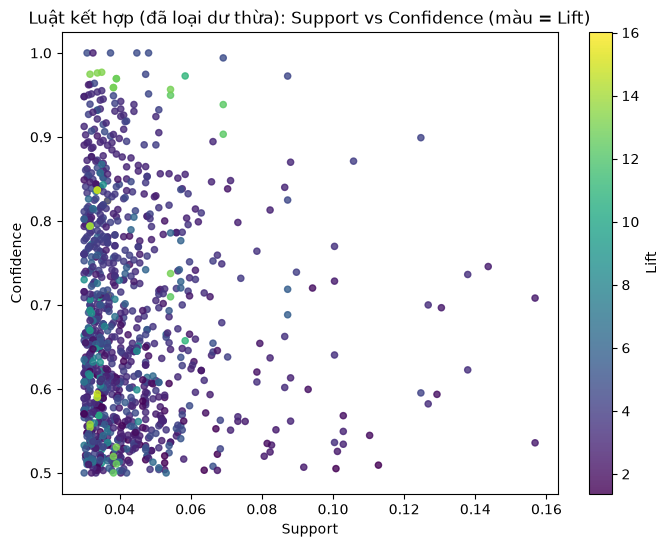

15 kỹ năng phổ biến nhất (các trục của heatmap): ['python', 'sql', 'ci/cd', 'docker', 'aws', 'java', 'agile', 'git', 'linux', 'devops', 'kubernetes', 'azure', 'rest api', 'microservices', 'postgresql']


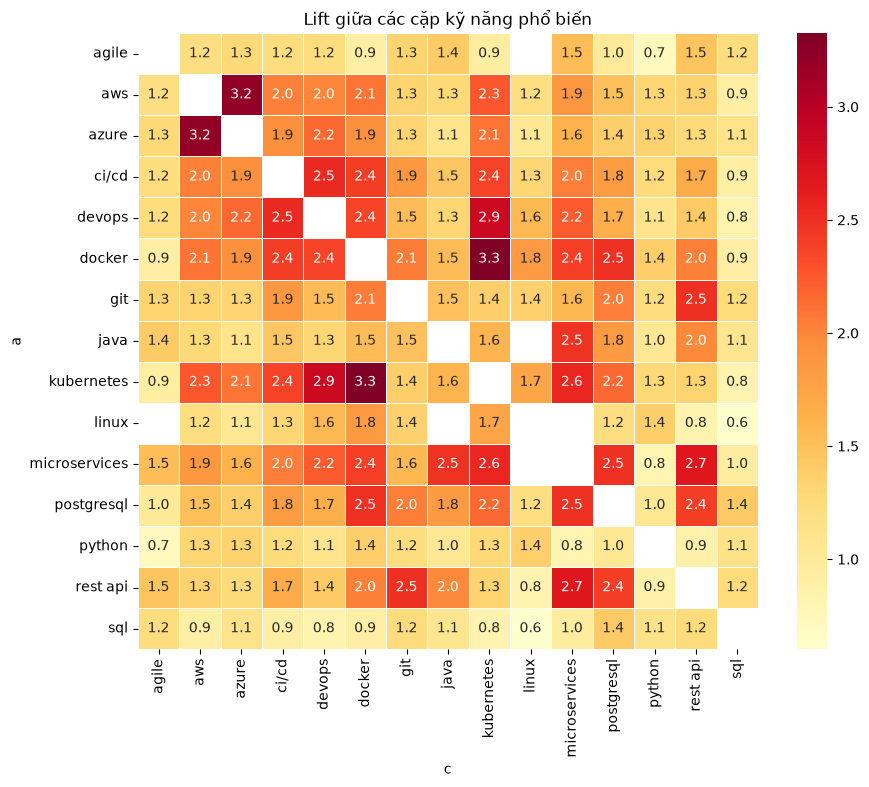

In [13]:
import os
os.makedirs('output', exist_ok=True)

# frozenset không lưu thẳng vào CSV được -> đổi thành chuỗi
fs = lambda x: ', '.join(sorted(x))

def csv_ready(rules_df):
    out = rules_df.copy()
    out['antecedents'] = out['antecedents'].apply(fs)
    out['consequents'] = out['consequents'].apply(fs)
    return out

# Luật qua lọc (có cột is_redundant, redundant_by) và luật còn lại sau khi loại dư thừa
csv_ready(rules_f).to_csv('output/association_rules_filtered.csv', index=False, encoding='utf-8-sig')
csv_ready(rules_nr).to_csv('output/association_rules_nonredundant.csv', index=False, encoding='utf-8-sig')

# Lưu tập phổ biến
fi = fi_fp.copy()
fi['itemsets'] = fi['itemsets'].apply(fs)
fi.to_csv('output/frequent_itemsets.csv', index=False, encoding='utf-8-sig')

plt.figure(figsize=(8, 6))
sc = plt.scatter(rules_nr['support'], rules_nr['confidence'], c=rules_nr['lift'], cmap='viridis', s=20, alpha=0.8)
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Luật kết hợp (đã loại dư thừa): Support vs Confidence (màu = Lift)')
plt.savefig('output/scatter_support_confidence.png', dpi=300, bbox_inches='tight')
plt.show()

top = onehot.mean().sort_values(ascending=False).head(15).index.tolist()
print("15 kỹ năng phổ biến nhất (các trục của heatmap):", top)
pairs = rules[(rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)].copy()
pairs['a'] = pairs['antecedents'].apply(lambda x: next(iter(x)))
pairs['c'] = pairs['consequents'].apply(lambda x: next(iter(x)))
hm = pairs[pairs['a'].isin(top) & pairs['c'].isin(top)].pivot(index='a', columns='c', values='lift')

plt.figure(figsize=(10, 8))
sns.heatmap(hm, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5)
plt.title('Lift giữa các cặp kỹ năng phổ biến')
plt.savefig('output/heatmap_lift.png', dpi=300, bbox_inches='tight')
plt.show()

## Phân tích Bước 2.4.12: Trực quan hóa

### Mục tiêu
Bảng số liệu cho chi tiết nhưng không cho thấy *cấu trúc tổng thể*. Hai biểu đồ dưới đây bổ sung cho nhau. Cả hai đã được lưu thành file PNG trong thư mục `output/` (lệnh `savefig` chạy **trước** `plt.show()`).

Ô code cũng lưu ba file CSV:

| File | Nội dung |
|---|---|
| `frequent_itemsets.csv` | 856 tập phổ biến |
| `association_rules_filtered.csv` | 1.228 luật qua lọc, có cột `is_redundant` và `redundant_by` |
| `association_rules_nonredundant.csv` | 1.027 luật sau khi loại dư thừa |

### Biểu đồ 1: Scatter Support × Confidence (màu = Lift)
Vẽ trên **1.027 luật đã loại dư thừa**.

- Mỗi chấm là một luật. Trục ngang là mức phổ biến, trục dọc là độ chắc chắn, màu sắc thể hiện độ gắn kết (lift).
- **Cách đọc:** luật lý tưởng nằm ở **góc trên bên phải** (phổ biến, chắc chắn, gắn kết mạnh).
- **Quan sát:**
  - 90,8% luật nằm ở support dưới 6% (trung vị 3,7%).
  - 62 luật có lift từ 8 trở lên đều là tổ hợp ngách (97% trong số đó có support dưới 6%).
  - Chỉ 8 luật có support ≥ 10% và confidence ≥ 70%, ví dụ `scrum ⇒ agile`, `kubernetes ⇒ docker`, `google cloud ⇒ aws`.
- **Nhận xét:** luật mạnh thường là luật chuyên biệt, không phải luật phổ biến.

### Biểu đồ 2: Heatmap Lift giữa các cặp trong 15 kỹ năng phổ biến nhất
15 trục là: python, sql, ci/cd, docker, aws, java, agile, git, linux, devops, kubernetes, rest api, azure, microservices, postgresql. Mỗi ô là lift của luật một-một `A ⇒ B` trong bộ luật **thô**, nên có cả những ô lift < 1,2.

- **Cách đọc:** ô càng đậm thì lift càng cao; **ô trống** nghĩa là cặp đó không có luật (không đạt support 0,03).
- **Ô đậm nhất:**

| Cặp | Lift |
|---|---:|
| `docker ⇄ kubernetes` | 3,33 |
| `aws ⇄ azure` | 3,22 |
| `kubernetes ⇄ devops` | 2,85 |
| `microservices ⇄ rest api` | 2,68 |

- **Hạn chế của heatmap:** không thể hiện cụm web front-end hay Java/Spring, vì `html`, `css`, `spring` không nằm trong 15 kỹ năng phổ biến nhất. Hai cụm đó nằm ở bảng top luật theo Lift (2.4.9). Scrum cũng không còn trong 15 trục sau khi loại 103 tin chưa xác nhận (70 tin trong số đó có Scrum), nên cặp `scrum ⇄ agile` (lift 3,94 ở mẫu chưa lọc) không còn trên heatmap.

---

## KẾT LUẬN CHUNG

### Quá trình đã làm
`3.135 tin` → `2.843 tin` (phạm vi IT sơ bộ và có JD sạch) → `2.430 giỏ kỹ năng` (bỏ 413 tin có dưới 2 kỹ năng; đây là mẫu số của mọi tỷ lệ) → `856 tập phổ biến` → `4.018 luật thô` → `1.228 luật qua lọc` → **`1.027 luật chất lượng`** sau khi loại 201 luật dư thừa.

### Phát hiện chính
1. **Các cụm kỹ năng rõ rệt** (từ bảng top luật): web front-end (HTML/CSS/JavaScript/React), mobile (Android + iOS), Java backend (Spring), DevOps/Cloud (Docker, Kubernetes, AWS, Azure) và Data/ML (ML ⇒ Python).
2. **Quan hệ có hướng:** 73,6% tin có Kubernetes cũng có Docker, so với 62,3% tin có Docker cũng có Kubernetes. Chênh lệch này đến từ việc Kubernetes ít phổ biến hơn Docker (455 so với 538 giỏ). Nó phù hợp với cách hiểu Docker là kỹ năng nền, nhưng dữ liệu JD không chứng minh điều đó.
3. **Phổ biến không đồng nghĩa với gắn kết:** Python và SQL nằm trong nhóm xuất hiện nhiều nhất nhưng lift chỉ 1,14 trên 2.430 giỏ, tức mức gắn kết thấp so với tần suất của chúng. Con số này nhạy với mẫu số (1,28 nếu tính trên 2.843 tin, xem 2.4.10b).
4. **Cần diễn giải thận trọng:** 5 luật confidence 100% còn lại chỉ phản ánh quan hệ kỹ thuật hiển nhiên (framework ⇒ ngôn ngữ, Scrum ⇒ Agile). `spring boot ⇒ java` chỉ 99,41% (168/169).
5. **"Không có luật" phải đi kèm điều kiện:** `{python, sql} ⇒ machine learning` vắng mặt chỉ vì tổ hợp ba kỹ năng có 56 giỏ (2,30%), dưới ngưỡng support 3% (73 giỏ); confidence của nó cũng chỉ 17,0%. Câu đúng là *"không tìm thấy luật ở ngưỡng support 3%"*, không phải *"ba kỹ năng không đi cùng nhau"*.

### Hạn chế
- Mẫu gồm 5 nguồn (TopCV 894, LinkedIn 591, ITviec 496, VietnamWorks 396, TopDev 53 giỏ) nhưng thu thập trong một đợt duy nhất, nên kết quả có thể không đại diện toàn thị trường và nghiêng về TopCV.
- Kỹ năng được trích bằng từ điển từ tiêu đề, thẻ và JD; không phân biệt kỹ năng "bắt buộc" và "ưu tiên".
- Kỹ năng đi cùng nhau chưa chắc có quan hệ nhân quả; luật kết hợp chỉ mô tả sự đồng xuất hiện trong tin tuyển dụng, không nói gì về năng lực của người học.
- Mọi tỷ lệ tính trên 2.430 giỏ (tin nêu ít nhất 2 kỹ năng), không phải trên toàn bộ 2.843 tin: đổi sang 2.843 tin thì support giảm khoảng 14,5% và lift tăng tới ×1,17 (xem 2.4.10b).
- Ngưỡng `MIN_SUP` (3%) là tham số quyết định và mang tính chủ quan, thay đổi sẽ thay đổi tập luật. `MIN_COUNT = 30` ít ảnh hưởng (cùng một bộ luật khi `MIN_COUNT` từ 30 đến 50) nhưng vẫn làm đổi mẫu số (xem 2.4.11b).
- 103 tin `pending_review` (nhiều Scrum Master/PM/BA) bị loại tạm thời; khi nhóm xác nhận phạm vi IT cuối cùng cần chạy lại.

### Hướng phát triển
- Gợi ý lộ trình học: "đã biết A, nên học B tiếp theo" dựa trên luật có lift và confidence cao (cần kiểm chứng thêm, vì luật chỉ mô tả cách nhà tuyển dụng liệt kê kỹ năng).
- Phân cụm công việc theo bộ kỹ năng (dùng thêm `text_for_tfidf`).
- Kết hợp với lương và kinh nghiệm (`Luong_TB`, `experience_group`) để xem cụm kỹ năng nào được trả cao hơn.